# Unidad 9A · Programación lineal
**Métodos Numéricos · Universidad del Pacífico · 2026-2**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ovelasquezc/metodos-numericos-up/blob/main/laboratorios/Programacion_Lineal_2026-2.ipynb)

En Colab, selecciona **Entorno de ejecución → Ejecutar todas**. La primera celda instala las bibliotecas. Los datos están incluidos en el cuaderno.

| Ejemplo | Qué vamos a observar |
|---|---|
| **BIM** | Región factible, pivotes y precio sombra del plástico. |
| **LAD** | Efecto de un dato atípico sobre dos criterios de ajuste. |
| **MAD** | Cambio de pesos y riesgo al exigir mayor retorno medio. |

Los apartados **Para experimentar** proponen cambios que puedes probar en las celdas.

## Preparación
SciPy permite resolver problemas lineales con HiGHS. Pyomo describe los modelos con variables, restricciones y objetivos, y usa el paquete highspy para resolverlos con HiGHS. [Instalación de Pyomo y solvers](https://mobook.github.io/MO-book/notebooks/appendix/installing-pyomo-and-solvers.html)

In [1]:
%pip install -q numpy scipy matplotlib pyomo highspy

Note: you may need to restart the kernel to use updated packages.


In [2]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.optimize import linprog

AZUL, VERDE, ORO, GRIS = "#003B70", "#13795B", "#A66300", "#506477"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.22,
    "font.size": 11,
})

## 1. BIM · Producción y recursos escasos

Sean $x_1$ y $x_2$ las cantidades de chips de cada tipo. El margen a maximizar es $12x_1+9x_2$.

| Insumo | Consumo por chip 1 | Consumo por chip 2 | Disponibilidad |
|---|---:|---:|---:|
| Silicio | 1 | 0 | 1000 |
| Germanio | 0 | 1 | 1500 |
| Plástico | 1 | 1 | 1750 |
| Cobre | 4 | 2 | 4800 |

Convertimos $Ax\le b$ en $Ax+s=b$ con holguras $s\ge 0$. Las holguras forman la base inicial. Cambiamos el signo del margen porque tanto el símplex docente como **linprog** están escritos para minimizar. [Modelo BIM del libro](https://mobook.github.io/MO-book/notebooks/02/01-bim.html)

In [3]:
c = np.array([12., 9.])
A = np.array([[1., 0.], [0., 1.], [1., 1.], [4., 2.]])
b = np.array([1000., 1500., 1750., 4800.])
insumos = ["Silicio", "Germanio", "Plástico", "Cobre"]

### 1.1. Un pivote del símplex, paso a paso

Ordenamos las variables de la forma estándar como $w=(x_1,x_2,s_1,s_2,s_3,s_4)$.
La matriz ampliada es $\tilde A=[A\mid I]$. Cada variable corresponde a una columna
de $\tilde A$.

Una **base** elige $m$ columnas linealmente independientes y las reúne en una matriz $B$.
Sus variables son **básicas**. Las demás son **no básicas** y se fijan en cero para
calcular la solución básica. Resolvemos $Bw_{\mathcal B}=b$.
Si $w_{\mathcal B}\ge0$, obtenemos una **solución básica factible**.
Una variable básica puede valer cero. En ese caso la solución básica factible
es **degenerada**.

**Paso A. Construir la base inicial.** Para BIM elegimos las columnas de las holguras.
Python numera las columnas desde cero. El vector de nombres permite leer la salida
sin convertir los índices a mano.

In [4]:
m, n = A.shape
A_estandar = np.column_stack((A, np.eye(m)))
c_estandar = np.r_[-c, np.zeros(m)]
nombres = np.array(["x1", "x2", "s1 (silicio)", "s2 (germanio)",
                    "s3 (plástico)", "s4 (cobre)"])

base_inicial = list(range(n, n + m))
no_basicas = [j for j in range(n + m) if j not in base_inicial]
B = A_estandar[:, base_inicial]
w_B = np.linalg.solve(B, b)

print("Variables básicas:", ", ".join(nombres[base_inicial]))
print("Valores básicos:", w_B)
print("Variables no básicas, fijadas en cero:", ", ".join(nombres[no_basicas]))

Variables básicas: s1 (silicio), s2 (germanio), s3 (plástico), s4 (cobre)
Valores básicos: [1000. 1500. 1750. 4800.]
Variables no básicas, fijadas en cero: x1, x2


**Lectura.** Como $B=I$, las variables básicas valen $b$. El plan de producción es
$(0,0)$ y queda disponible todo el inventario.

**Paso B. Elegir la variable entrante.** Primero resolvemos $B^\top y=\tilde c_{\mathcal B}$.
Luego calculamos $\bar c_j=\tilde c_j-a_j^\top y$, donde $a_j$ es la columna de
$\tilde A$ asociada a la variable $j$. El **costo reducido** es el cambio en el objetivo
por unidad de aumento de esa variable no básica, ajustando las básicas para mantener
las igualdades. En minimización, un costo reducido negativo indica una dirección
de mejora si existe un paso positivo factible. La regla de Bland elige el menor
índice entre las variables no básicas con costo reducido negativo.

In [5]:
tol = 1e-9
y_dual = np.linalg.solve(B.T, c_estandar[base_inicial])
reducidos = c_estandar - A_estandar.T @ y_dual
elegibles = [j for j in no_basicas if reducidos[j] < -tol]
if not elegibles:
    raise RuntimeError("La base inicial ya es óptima.")

entra = min(elegibles)
for j in no_basicas:
    print(f"{nombres[j]}: costo reducido = {reducidos[j]:g}")
print(f"Entra {nombres[entra]} por la regla de Bland.")

x1: costo reducido = -12
x2: costo reducido = -9
Entra x1 por la regla de Bland.


**Lectura.** Los costos reducidos son $-12$ y $-9$. Ambas variables son elegibles.
Bland elige $x_1$, que tiene el menor índice.

**Paso C. Calcular cuánto podemos avanzar.** Si la entrante aumenta en $t$,
las básicas quedan en $w_{\mathcal B}-tu$, donde $Bu=a_j$.
Solo las filas con $u_i>0$ limitan el paso, porque en esas filas la variable
básica disminuye. El mínimo de $w_{\mathcal B,i}/u_i$ determina el paso máximo
$t_*$ y la variable saliente. Si hay empate, Bland elige la básica de menor
índice. Si ninguna básica disminuye, el objetivo puede mejorar sin límite
por esa dirección.

In [6]:
u = np.linalg.solve(B, A_estandar[:, entra])
filas = np.flatnonzero(u > 0)
if filas.size == 0:
    raise RuntimeError("La dirección de mejora no tiene paso máximo.")

cocientes = {i: max(w_B[i], 0.0) / u[i] for i in filas}
fila_sale = min(filas, key=lambda i: (cocientes[i], base_inicial[i]))
paso_maximo = cocientes[fila_sale]
sale = base_inicial[fila_sale]

print("Dirección u:", u)
for i in filas:
    print(f"{nombres[base_inicial[i]]}: {w_B[i]:g} / {u[i]:g} = {cocientes[i]:g}")
print(f"Paso máximo: {paso_maximo:g}. Sale {nombres[sale]}.")

Dirección u: [1. 0. 1. 4.]
s1 (silicio): 1000 / 1 = 1000
s3 (plástico): 1750 / 1 = 1750
s4 (cobre): 4800 / 4 = 1200
Paso máximo: 1000. Sale s1 (silicio).


**Lectura.** Los cocientes del silicio, plástico y cobre son $1000$, $1750$ y $1200$.
La holgura de germanio tiene $u_i=0$ y conserva su valor. El silicio se agota primero.
Su restricción queda **activa**, es decir, se cumple con igualdad y su holgura vale cero.

**Paso D. Actualizar la base y comprobar el nuevo punto.** Un **pivote** sustituye
la columna saliente por la entrante. Formamos la nueva base, fijamos las nuevas
variables no básicas en cero y volvemos a resolver el sistema.

In [7]:
base_nueva = base_inicial.copy()
base_nueva[fila_sale] = entra
w_nuevo = np.zeros(n + m)
w_nuevo[base_nueva] = np.linalg.solve(A_estandar[:, base_nueva], b)

assert np.allclose(A_estandar @ w_nuevo, b)
assert np.all(w_nuevo >= -tol)
assert np.isclose(w_nuevo[entra], paso_maximo)

print("Nueva base:", ", ".join(nombres[base_nueva]))
print("Plan:", w_nuevo[:n])
print("Holguras:", w_nuevo[n:])
print(f"Margen: {c @ w_nuevo[:n]:,.0f}")

Nueva base: x1, s2 (germanio), s3 (plástico), s4 (cobre)
Plan: [1000.    0.]
Holguras: [   0. 1500.  750.  800.]
Margen: 12,000


**Lectura.** El primer pivote lleva de $(0,0)$ a $(1000,0)$, con margen de $12\,000$.
El segundo pivote incorpora $x_2$ y agota el cobre. El tercero vuelve a incorporar
la holgura de silicio y agota el plástico.

### 1.2. Recorrido completo y comparación con SciPy

La función general repite estos cálculos desde la base de holguras hasta que no
queda un costo reducido negativo o se detecta una dirección no acotada.
La siguiente ejecución comprueba que su primera base nueva y su primer plan
coinciden con lo que acabamos de calcular.

In [8]:
def simplex_revisado(A, b, c, base, tol=1e-9, max_pivotes=100):
    """Minimiza c @ x con A @ x = b y x >= 0 desde una base factible.

    Los índices de la base comienzan en cero. La trayectoria guarda cada
    par (base, x) visitado. Devuelve (x, trayectoria, None) al encontrar
    un óptimo o (None, trayectoria, rayo) si detecta no acotación.
    La tolerancia absoluta está pensada para ejemplos bien escalados.
    """
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    c = np.asarray(c, dtype=float)
    m, n = A.shape
    base = list(base)
    if b.shape != (m,) or c.shape != (n,):
        raise ValueError("Las dimensiones de A, b y c deben coincidir.")
    if len(base) != m or len(set(base)) != m:
        raise ValueError("La base debe tener m índices distintos.")
    if any(not isinstance(j, (int, np.integer)) or not 0 <= j < n for j in base):
        raise ValueError("Los índices básicos deben ser enteros entre 0 y n-1.")

    trayectoria = []
    for pivotes in range(max_pivotes + 1):
        B = A[:, base]
        x_B = np.linalg.solve(B, b)
        if np.any(x_B < -tol):
            raise ValueError("La base debe ser factible dentro de la tolerancia.")

        x = np.zeros(n)
        x[base] = x_B
        trayectoria.append((tuple(base), x))

        y = np.linalg.solve(B.T, c[base])
        reducidos = c - A.T @ y
        # Bland: primera variable no básica con costo reducido negativo.
        entra = next(
            (j for j in range(n) if j not in base and reducidos[j] < -tol),
            None,
        )
        if entra is None:
            return x, trayectoria, None

        u = np.linalg.solve(B, A[:, entra])
        filas = np.flatnonzero(u > 0)
        if filas.size == 0:
            rayo = np.zeros(n)
            rayo[base] = -u
            rayo[entra] = 1
            return None, trayectoria, rayo

        if pivotes == max_pivotes:
            break
        # El segundo componente desempata por índice de variable básica.
        sale = min(filas, key=lambda i: (max(x_B[i], 0.0) / u[i], base[i]))
        base[sale] = entra

    raise RuntimeError("Se alcanzó el límite de pivotes.")

In [9]:
x, trayectoria, rayo = simplex_revisado(
    A_estandar, b, c_estandar, base=base_inicial
)
if rayo is not None:
    raise RuntimeError("Se esperaba un óptimo finito en BIM.")
assert trayectoria[1][0] == tuple(base_nueva)
assert np.allclose(trayectoria[1][1], w_nuevo)

def resolver_bim(disponibilidad):
    resultado = linprog(-c, A_ub=A, b_ub=disponibilidad, method="highs")
    if not resultado.success:
        raise RuntimeError(resultado.message)
    return resultado

bim = resolver_bim(b)
assert np.allclose(x[:n], bim.x)
planes = np.array([punto[:n] for _, punto in trayectoria])
margenes = planes @ c

print("Paso   Base (índices desde 1)   Plan (x₁, x₂)     Margen")
for paso, ((indices_base, _), plan, margen) in enumerate(zip(trayectoria, planes, margenes)):
    indices = tuple(j + 1 for j in indices_base)
    punto = f"({plan[0]:.0f}, {plan[1]:.0f})"
    print(f"{paso:>4}   {str(indices):<21}   {punto:<16} {margen:>7,.0f}")
print(f"\nÓptimo de HiGHS: {bim.x}   Margen: {-bim.fun:,.0f}")

Paso   Base (índices desde 1)   Plan (x₁, x₂)     Margen
   0   (3, 4, 5, 6)            (0, 0)                 0
   1   (1, 4, 5, 6)            (1000, 0)         12,000
   2   (1, 4, 5, 2)            (1000, 400)       15,600
   3   (1, 4, 3, 2)            (650, 1100)       17,700

Óptimo de HiGHS: [ 650. 1100.]   Margen: 17,700


### 1.3. Región factible y pivotes
El gráfico reconstruye los vértices a partir de las restricciones y superpone la trayectoria calculada por el símplex. La recta punteada muestra el último nivel de margen que toca la región.

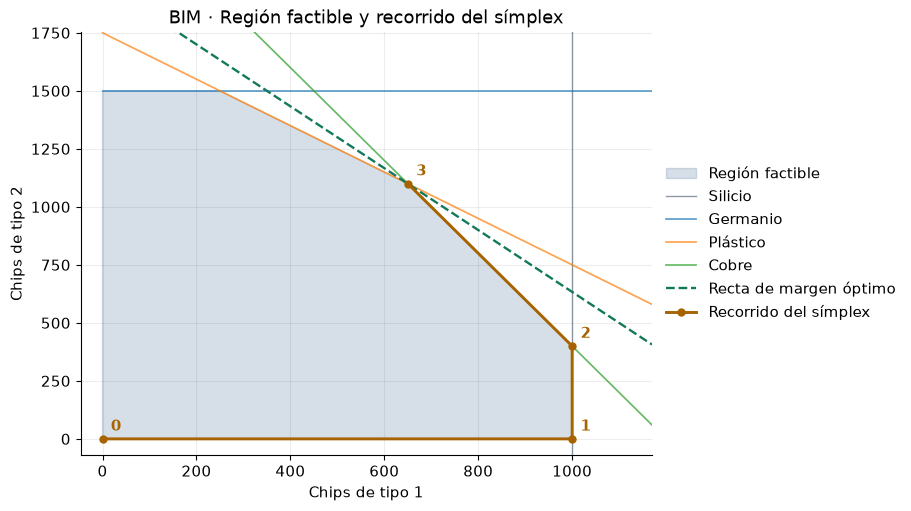

In [10]:
filas = np.vstack([A, -np.eye(n)])
limites = np.r_[b, 0., 0.]
vertices = []
for i, j in combinations(range(len(filas)), 2):
    sistema = filas[[i, j]]
    if abs(np.linalg.det(sistema)) > 1e-10:
        punto = np.linalg.solve(sistema, limites[[i, j]])
        if np.all(filas @ punto <= limites + 1e-8):
            vertices.append(punto)

vertices = np.unique(np.array(vertices), axis=0)
desplazados = vertices - vertices.mean(axis=0)
orden = np.argsort(np.arctan2(desplazados[:, 1], desplazados[:, 0]))
poligono = vertices[orden]
lim_x, lim_y = 1.17 * vertices.max(axis=0)
eje_x = np.linspace(0, lim_x, 200)

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.fill(*poligono.T, color=AZUL, alpha=.16, label="Región factible")
for (a1, a2), limite, nombre in zip(A, b, insumos):
    if a2 == 0:
        ax.axvline(limite / a1, color=GRIS, alpha=.65, lw=1, label=nombre)
    else:
        ax.plot(eje_x, (limite - a1 * eje_x) / a2,
                alpha=.72, lw=1.25, label=nombre)
ax.plot(eje_x, (-bim.fun - c[0] * eje_x) / c[1], "--", color=VERDE,
        lw=1.7, label="Recta de margen óptimo")
ax.plot(*planes.T, "o-", color=ORO, lw=2.1, ms=5, label="Recorrido del símplex")
for paso, plan in enumerate(planes):
    ax.annotate(str(paso), plan, xytext=(6, 6), textcoords="offset points",
                color=ORO, weight="bold")
ax.set(xlim=(-.04 * lim_x, lim_x), ylim=(-.04 * lim_y, lim_y),
       xlabel="Chips de tipo 1", ylabel="Chips de tipo 2",
       title="BIM · Región factible y recorrido del símplex")
ax.legend(loc="center left", bbox_to_anchor=(1, .5), frameon=False)
plt.show()

### 1.4. Precio sombra del plástico
En $(650,1100)$ quedan $350$ unidades de silicio y $400$ de germanio. Plástico y cobre se agotan. Los marginales de **linprog** corresponden a la minimización de $-c^\top x$. Cambiamos su signo para interpretar el máximo.

El precio sombra del plástico es **6 unidades monetarias por unidad de plástico** en el punto de referencia. El gráfico compara el margen óptimo recalculado con esa aproximación local. [Documentación de linprog](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html) · [Dual de BIM](https://mobook.github.io/MO-book/notebooks/02/06-bim-dual.html)

  Silicio   Holgura:   350   Precio sombra: 0.0
 Germanio   Holgura:   400   Precio sombra: 0.0
 Plástico   Holgura:     0   Precio sombra: 6.0
    Cobre   Holgura:     0   Precio sombra: 1.5

Una unidad adicional de plástico aumenta el margen en 6.00.


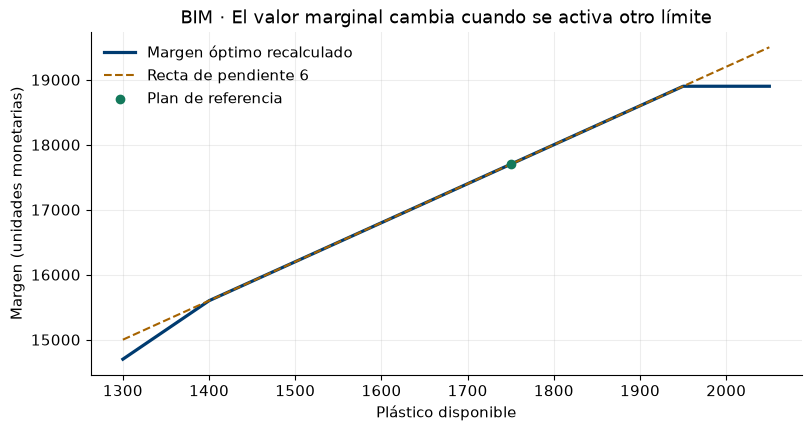

In [11]:
holguras = b - A @ bim.x
precios_sombra = -bim.ineqlin.marginals
for insumo, holgura, precio in zip(insumos, holguras, precios_sombra):
    print(f"{insumo:>9}   Holgura: {holgura:>5.0f}   Precio sombra: {precio:.1f}")

# Para experimentar: cambia el rango de disponibilidad de plástico.
plasticos = np.linspace(1300, 2050, 31)
base_plastico = b[2]
margen_base = -bim.fun

def valor_con_plastico(plastico):
    rhs = b.copy()
    rhs[2] = plastico
    return -resolver_bim(rhs).fun

ganancia = valor_con_plastico(base_plastico + 1) - margen_base
print(f"\nUna unidad adicional de plástico aumenta el margen en {ganancia:.2f}.")

valores = np.array([valor_con_plastico(p) for p in plasticos])
aproximacion = margen_base + precios_sombra[2] * (plasticos - base_plastico)

fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.plot(plasticos, valores, lw=2.3, color=AZUL, label="Margen óptimo recalculado")
ax.plot(plasticos, aproximacion, "--", color=ORO, label="Recta de pendiente 6")
ax.scatter(base_plastico, margen_base, color=VERDE, zorder=3, label="Plan de referencia")
ax.set(xlabel="Plástico disponible", ylabel="Margen (unidades monetarias)",
       title="BIM · El valor marginal cambia cuando se activa otro límite")
ax.legend(frameon=False)
plt.show()

**Para experimentar.** Aumenta el silicio en una unidad al llamar a **resolver_bim** y compara el nuevo margen con el original. En el gráfico, ubica a partir de qué disponibilidad adicional de plástico la recta sobreestima el margen.

## 2. LAD · Regresión de mínima suma de desviaciones absolutas

**LAD** significa *Least Absolute Deviation*. Buscamos una recta que minimice la suma de las distancias verticales a los datos. Separamos cada residuo como $p_i-q_i$ con $p_i,q_i\geq0$ y minimizamos $\sum_i (p_i+q_i)$.

Las dos funciones siguientes se usan en ambos ejemplos de Pyomo. **crear_solver** comprueba la disponibilidad de HiGHS. **resolver** verifica la terminación antes de cargar valores. [Formulación LAD del libro](https://mobook.github.io/MO-book/notebooks/02/02-lad-regression.html#model)

In [12]:
import pyomo.environ as pyo


def crear_solver():
    solver = pyo.SolverFactory("appsi_highs")
    if not solver.available(exception_flag=False):
        raise RuntimeError("HiGHS requiere el paquete highspy.")
    return solver


def resolver(modelo, solver):
    resultado = solver.solve(modelo, load_solutions=False)
    pyo.assert_optimal_termination(resultado)
    modelo.solutions.load_from(resultado)


solver = crear_solver()

In [13]:
# Para experimentar: modifica el gasto de la tercera observación.
z = np.array([0, 1, 2, 3, 4], dtype=float)
y = np.array([1, 3, 15, 7, 9], dtype=float)

lad = pyo.ConcreteModel("LAD")
lad.I = pyo.RangeSet(0, len(y) - 1)
lad.alpha = pyo.Var(domain=pyo.Reals)
lad.beta = pyo.Var(domain=pyo.Reals)
lad.p = pyo.Var(lad.I, domain=pyo.NonNegativeReals)
lad.q = pyo.Var(lad.I, domain=pyo.NonNegativeReals)

@lad.Constraint(lad.I)
def residuo(m, i):
    return m.alpha + z[i] * m.beta + m.p[i] - m.q[i] == y[i]

lad.error = pyo.Objective(
    expr=sum(lad.p[i] + lad.q[i] for i in lad.I), sense=pyo.minimize,
)
resolver(lad, solver)
alpha, beta = pyo.value(lad.alpha), pyo.value(lad.beta)
ajuste_lad = alpha + beta * z

X = np.column_stack((np.ones_like(z), z))
alpha_mc, beta_mc = np.linalg.lstsq(X, y, rcond=None)[0]
ajuste_mc = alpha_mc + beta_mc * z
print(f"LAD: intercepto {alpha:.2f}, pendiente {beta:.2f}, suma absoluta {pyo.value(lad.error):.2f}")
print(f"Mínimos cuadrados: intercepto {alpha_mc:.2f}, pendiente {beta_mc:.2f}, suma absoluta {abs(y - ajuste_mc).sum():.2f}")

LAD: intercepto 1.00, pendiente 2.00, suma absoluta 10.00
Mínimos cuadrados: intercepto 3.00, pendiente 2.00, suma absoluta 16.00


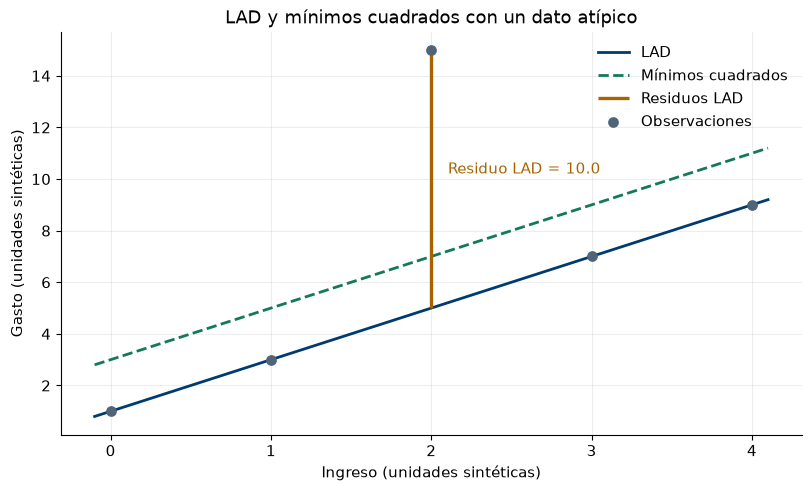

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.8), layout="constrained")
eje_z = np.linspace(z.min() - .1, z.max() + .1, 200)
ax.plot(eje_z, alpha + beta * eje_z, color=AZUL, lw=2, label="LAD")
ax.plot(eje_z, alpha_mc + beta_mc * eje_z, "--", color=VERDE,
        lw=2, label="Mínimos cuadrados")
ax.vlines(z, ajuste_lad, y, color=ORO, lw=2.4, label="Residuos LAD")
ax.scatter(z, y, color=GRIS, s=45, zorder=3, label="Observaciones")
atipico = np.argmax(abs(y - ajuste_lad))
ax.annotate(f"Residuo LAD = {y[atipico] - ajuste_lad[atipico]:.1f}",
            (z[atipico], (y[atipico] + ajuste_lad[atipico]) / 2),
            xytext=(12, 4), textcoords="offset points", color=ORO)
ax.set(xlabel="Ingreso (unidades sintéticas)", ylabel="Gasto (unidades sintéticas)",
       title="LAD y mínimos cuadrados con un dato atípico")
ax.legend(frameon=False)
plt.show()

La recta LAD $\hat y=1+2z$ pasa por cuatro observaciones. En $z=2$ predice $5$, frente al gasto observado de $15$. El residuo de $10$ explica toda la suma de errores absolutos. Mínimos cuadrados desplaza la recta hacia arriba y obtiene un intercepto de $3$. Cada criterio optimiza una pérdida distinta.

**Para experimentar.** Sustituye el gasto de $15$ por $20$ y vuelve a ejecutar las dos celdas anteriores. Compara los interceptos.

## 3. MAD · Cartera de mínima desviación absoluta media

**MAD** significa *Mean Absolute Deviation*. Primero combinamos los retornos de los activos con sus pesos. Después medimos la distancia absoluta promedio de ese retorno a su media muestral. Los pesos son no negativos, suman uno y cada uno tiene un tope de $80\%$.

La meta $R$ es mutable. Resolvemos el mismo modelo con distintos valores de $R$ para observar cómo varía el riesgo mínimo. Los datos son sintéticos. [Modelo MAD del libro](https://mobook.github.io/MO-book/notebooks/02/03-mad-portfolio-optimization.html#mean-absolute-deviation-mad-portfolio-optimization)

In [15]:
def modelo_mad():
    """Construye una cartera de dos activos y cuatro períodos."""
    r = {"A": (0.00, 0.02, 0.06, 0.08),
         "B": (0.04, 0.03, 0.01, 0.00)}
    media = {j: sum(serie) / len(serie) for j, serie in r.items()}

    m = pyo.ConcreteModel("Cartera MAD")
    m.J = pyo.Set(initialize=list(r))
    m.T = pyo.RangeSet(0, len(r["A"]) - 1)
    m.R = pyo.Param(initialize=0.03, mutable=True)
    m.w = pyo.Var(m.J, bounds=(0, 0.8))
    m.p = pyo.Var(m.T, domain=pyo.NonNegativeReals)
    m.q = pyo.Var(m.T, domain=pyo.NonNegativeReals)

    @m.Constraint(m.T)
    def desvio(m, t):
        return m.p[t] - m.q[t] == sum(
            (r[j][t] - media[j]) * m.w[j] for j in m.J
        )

    m.presupuesto = pyo.Constraint(expr=sum(m.w.values()) == 1)
    m.retorno = pyo.Expression(expr=sum(media[j] * m.w[j] for j in m.J))
    m.meta = pyo.Constraint(expr=m.retorno >= m.R)
    m.riesgo = pyo.Objective(
        expr=sum(m.p[t] + m.q[t] for t in m.T) / len(m.T),
        sense=pyo.minimize,
    )
    return m

In [16]:
mad = modelo_mad()

def cartera_con_meta(meta):
    mad.R.set_value(meta)
    resolver(mad, solver)
    pesos = np.array([pyo.value(mad.w[j]) for j in mad.J])
    return pesos, pyo.value(mad.retorno), pyo.value(mad.riesgo)

metas = (0.03, 0.035)
escenarios = [cartera_con_meta(meta) for meta in metas]
filas_tabla = [
    "| Meta R | Peso A | Peso B | Retorno medio | MAD (p. p.) |",
    "|---:|---:|---:|---:|---:|",
]
for meta, (pesos, retorno, riesgo) in zip(metas, escenarios):
    filas_tabla.append(
        f"| {meta:.1%} | {pesos[0]:.1%} | {pesos[1]:.1%} | {retorno:.3%} | {100 * riesgo:.3f} |"
    )
display(Markdown("\n".join(filas_tabla)))

| Meta R | Peso A | Peso B | Retorno medio | MAD (p. p.) |
|---:|---:|---:|---:|---:|
| 3.0% | 50.0% | 50.0% | 3.000% | 0.750 |
| 3.5% | 75.0% | 25.0% | 3.500% | 1.875 |

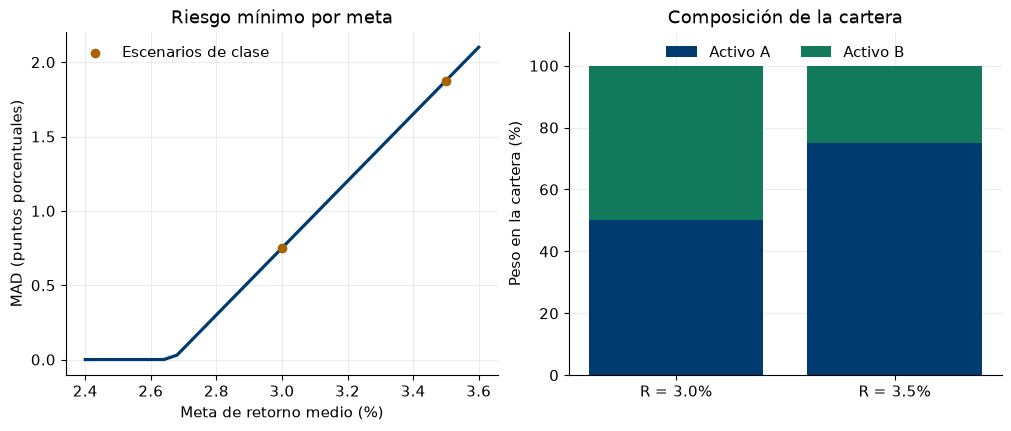

In [17]:
metas_grafico = np.linspace(.024, .036, 31)
riesgos = [100 * cartera_con_meta(meta)[2] for meta in metas_grafico]
pesos_escenarios = 100 * np.array([escenario[0] for escenario in escenarios])
etiquetas = [f"R = {meta:.1%}" for meta in metas]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
ax1.plot(100 * metas_grafico, riesgos, color=AZUL, lw=2.3)
ax1.scatter(100 * np.array(metas), [100 * e[2] for e in escenarios],
            color=ORO, zorder=3, label="Escenarios de clase")
ax1.set(xlabel="Meta de retorno medio (%)", ylabel="MAD (puntos porcentuales)",
        title="Riesgo mínimo por meta")
ax1.legend(frameon=False)
ax2.bar(etiquetas, pesos_escenarios[:, 0], color=AZUL, label="Activo A")
ax2.bar(etiquetas, pesos_escenarios[:, 1], bottom=pesos_escenarios[:, 0],
        color=VERDE, label="Activo B")
ax2.set(ylim=(0, 111), ylabel="Peso en la cartera (%)", title="Composición de la cartera")
ax2.legend(loc="upper center", ncol=2, frameon=False)
plt.show()

Al elevar la meta del **3 % al 3,5 %**, el peso de A sube del **50 % al 75 %** y el MAD sube de **0,750 a 1,875 puntos porcentuales**. En esta muestra, el mayor peso de A reduce la compensación entre las variaciones de ambos activos.

### 3.1. Detectar una meta infactible
A rinde en promedio un 4 % y B un 2 %. Con el tope de 80 % en A, el retorno máximo es 3,6 %. La siguiente celda consulta el estado de una meta de 4 % con la carga automática desactivada.

In [18]:
# Para experimentar: prueba 0.036 y 0.037 en este modelo separado.
prueba = modelo_mad()
prueba.R.set_value(0.04)
estado = solver.solve(prueba, load_solutions=False)
print("Terminación:", estado.solver.termination_condition)

Terminación: infeasible


## Cierre

- En BIM, identifica qué insumos se agotan y comprueba cuánto vale agregar una unidad.
- En LAD, localiza el residuo que aporta el error absoluto total.
- En MAD, distingue el retorno medio exigido, el retorno que se alcanza y la desviación absoluta media.